# Projeto Final - Machine Learning

## Previsão do Valor de Financiamento Habitacional do Programa Minha Casa Minha Vida (MCMV)

### Contexto

O Programa Minha Casa Minha Vida (MCMV) é uma das principais iniciativas de política habitacional do Brasil, voltada à ampliação do acesso à moradia por meio de mecanismos de financiamento e subsídios habitacionais.

A base utilizada neste projeto contém aproximadamente 7,8 milhões de registros de operações de financiamento habitacional e 21 variáveis. Entre as informações disponíveis estão localização geográfica, renda familiar, valor de compra do imóvel, subsídios, taxa de juros e características da operação.

### Problema

Dadas as características disponíveis das operações de financiamento habitacional, é possível estimar o valor do financiamento concedido no Programa Minha Casa Minha Vida?

Além da capacidade preditiva, o projeto busca investigar quais características disponíveis na base apresentam maior contribuição para a estimativa do valor financiado.

### Objetivo

Desenvolver e avaliar modelos de Machine Learning capazes de estimar o valor do financiamento habitacional concedido no âmbito do Programa Minha Casa Minha Vida, utilizando as características disponíveis das operações.

### Variável-alvo (Target)

A variável-alvo será:

`vlr_financiamento`

Essa variável representa o valor do financiamento habitacional e constitui a variável numérica que os modelos tentarão estimar.

### Tipo de problema

- Aprendizado supervisionado
- Regressão

O problema é caracterizado como regressão porque a variável-alvo `vlr_financiamento` é uma variável numérica contínua.

### Variáveis candidatas

A base contém informações potencialmente explicativas relacionadas a:

- localização geográfica;
- renda familiar;
- valor de compra do imóvel;
- subsídios concedidos;
- taxa de juros;
- programa habitacional;
- tipo do imóvel;
- condição de cotista;
- sistema de amortização;
- compatibilidade com faixa de renda;
- características temporais da operação.

As variáveis efetivamente utilizadas nos modelos serão definidas após a análise exploratória dos dados e a avaliação de possível vazamento de informações (data leakage).

Uma variável somente deverá ser utilizada como preditora caso sua utilização seja metodologicamente adequada ao momento em que a previsão seria realizada.

### Hipótese inicial

Parte-se da hipótese de que características econômicas, geográficas e contratuais das operações apresentam capacidade preditiva sobre o valor do financiamento.

Será investigada especialmente a relação entre `vlr_financiamento` e variáveis como renda familiar, valor de compra do imóvel, subsídios, localização e condições da operação.

Essa hipótese será avaliada empiricamente durante a análise exploratória e a modelagem, sem pressupor previamente quais variáveis deverão compor o modelo final.

### Estratégia de modelagem

Inicialmente será utilizado um modelo simples como baseline, estabelecendo uma referência mínima de desempenho.

Posteriormente, diferentes algoritmos de regressão serão treinados e comparados.

O projeto buscará avaliar não apenas o desempenho preditivo, mas também aspectos relacionados a:

- generalização do modelo;
- overfitting;
- vazamento de informações;
- pré-processamento das variáveis;
- interpretação dos resultados;
- limitações do modelo.

### Métricas de avaliação

Os modelos serão avaliados principalmente pelas seguintes métricas:

- **MAE (Mean Absolute Error):** erro absoluto médio das previsões;
- **RMSE (Root Mean Squared Error):** medida de erro que penaliza mais fortemente erros elevados;
- **R² (Coeficiente de Determinação):** proporção da variabilidade da variável-alvo explicada pelo modelo.

O MAE terá especial relevância por permitir interpretar o erro médio do modelo diretamente em reais (R$), mesma unidade da variável `vlr_financiamento`.

### Resultado esperado

Espera-se construir um fluxo completo de Machine Learning, abrangendo análise exploratória, pré-processamento, treinamento, validação e comparação de modelos de regressão.

Ao final, pretende-se identificar o desempenho dos modelos, suas principais limitações e as características das operações que mais contribuem para a previsão do valor financiado.

## 2. Fonte, Obtenção e Validação dos Dados

### Fonte dos dados

A base utilizada contém dados do Programa Minha Casa Minha Vida (MCMV), disponibilizados pelo Ministério das Cidades.

O conjunto de dados é distribuído em arquivo compactado no formato ZIP e contém registros de operações de financiamento habitacional.

### Aquisição dos dados

Para tornar o projeto reproduzível, a obtenção da base foi automatizada no próprio notebook.

O processo consiste em:

1. verificar se a base já está disponível localmente;
2. realizar o download do arquivo compactado quando necessário;
3. validar o arquivo obtido;
4. descompactar o CSV automaticamente;
5. manter os arquivos de dados fora do versionamento Git.

### Validação inicial

Antes da análise exploratória, serão verificados:

- existência e tamanho do arquivo;
- estrutura do conjunto de dados;
- quantidade de variáveis;
- nomes das colunas;
- tipos inicialmente identificados;
- capacidade de leitura adequada do CSV.

Nesta etapa não serão realizadas transformações nos dados.

In [1]:
## Obtenção e preparação da base original

""" from pathlib import Path
from urllib.request import urlretrieve
import zipfile

# URL oficial da base
URL = "https://www.cidades.gov.br/images/stories/ArquivosSNH/ArquivosZIP/mcmv_financ_analitico_20260724.zip"

# Como o notebook está em /notebooks, a raiz é um nível acima
PROJETO = Path.cwd().parent
PASTA_DADOS = PROJETO / "data"

ARQUIVO_ZIP = PASTA_DADOS / "mcmv_financ_analitico_20260724.zip"
ARQUIVO_CSV = PASTA_DADOS / "mcmv_financ_analitico_20260724.csv"

# Cria a pasta data, caso ainda não exista
PASTA_DADOS.mkdir(parents=True, exist_ok=True)

# Baixa somente se o CSV ainda não estiver disponível
if not ARQUIVO_CSV.exists():

    if not ARQUIVO_ZIP.exists():
        print("Baixando a base MCMV...")
        urlretrieve(URL, ARQUIVO_ZIP)
        print("Download concluído.")

    print("Descompactando a base...")

    with zipfile.ZipFile(ARQUIVO_ZIP, "r") as zip_ref:
        zip_ref.extractall(PASTA_DADOS)

    print("Descompactação concluída.")

else:
    print("Base já disponível localmente.")

print(f"Arquivo: {ARQUIVO_CSV}") """

' from pathlib import Path\nfrom urllib.request import urlretrieve\nimport zipfile\n\n# URL oficial da base\nURL = "https://www.cidades.gov.br/images/stories/ArquivosSNH/ArquivosZIP/mcmv_financ_analitico_20260724.zip"\n\n# Como o notebook está em /notebooks, a raiz é um nível acima\nPROJETO = Path.cwd().parent\nPASTA_DADOS = PROJETO / "data"\n\nARQUIVO_ZIP = PASTA_DADOS / "mcmv_financ_analitico_20260724.zip"\nARQUIVO_CSV = PASTA_DADOS / "mcmv_financ_analitico_20260724.csv"\n\n# Cria a pasta data, caso ainda não exista\nPASTA_DADOS.mkdir(parents=True, exist_ok=True)\n\n# Baixa somente se o CSV ainda não estiver disponível\nif not ARQUIVO_CSV.exists():\n\n    if not ARQUIVO_ZIP.exists():\n        print("Baixando a base MCMV...")\n        urlretrieve(URL, ARQUIVO_ZIP)\n        print("Download concluído.")\n\n    print("Descompactando a base...")\n\n    with zipfile.ZipFile(ARQUIVO_ZIP, "r") as zip_ref:\n        zip_ref.extractall(PASTA_DADOS)\n\n    print("Descompactação concluída.")\n\ne

### Recorte temporal da análise

A base completa contém 7.849.882 registros, com contratações realizadas entre 02/01/2009 e 23/07/2026.

Para este projeto, optou-se por analisar as operações contratadas a partir de 01/01/2020.

O objetivo do recorte é concentrar a análise em um período mais recente das operações habitacionais, reduzindo a influência de períodos históricos potencialmente sujeitos a contextos econômicos, regras e condições de financiamento distintas.

O recorte preserva 3.288.670 registros, correspondentes a 41,89% da base original, mantendo volume expressivo de dados para análise e modelagem.

A influência do tempo sobre os dados ainda será considerada durante a análise exploratória e na estratégia de validação do modelo.

In [2]:
from pathlib import Path
import pandas as pd
import os
from tkinter import filedialog, Tk
from datetime import datetime
from concurrent.futures import ThreadPoolExecutor, TimeoutError

ARQUIVO_BASE = "mcmv_financiamentos_2020_2026.zip"
caminho_completo = False

# Verifica se está rodando no Google Colab
try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB and not os.path.exists(ARQUIVO_BASE):
    from google.colab import files
    print(f"Por favor, faça o upload do arquivo: {ARQUIVO_BASE}")
    uploaded = files.upload()
    # 1. Pega o nome do arquivo enviado
    nome_arquivo = list(uploaded.keys())[0]
    # 2. Descobre o diretório atual do Colab (geralmente é '/content')
    diretorio_atual = os.getcwd()
    # 3. Junta os dois para ter o caminho completo absoluto dentro do Colab
    caminho_completo = os.path.abspath(os.path.join(diretorio_atual, nome_arquivo))
    PROJETO = os.path.dirname(caminho_completo)
elif os.path.exists(ARQUIVO_BASE):
    # 1. Pega o nome do arquivo enviado
    nome_arquivo = ARQUIVO_BASE
    # 2. Descobre o diretório atual do Colab (geralmente é '/content')
    diretorio_atual = os.getcwd()
    # 3. Junta os dois para ter o caminho completo absoluto dentro do Colab
    caminho_completo = os.path.abspath(os.path.join(diretorio_atual, nome_arquivo))
    PROJETO = os.path.dirname(caminho_completo)
else:
    # Localiza a raiz do projeto, mesmo que o notebook
    # esteja sendo executado dentro da pasta notebooks

    # Isolamos a lógica do 'next' em uma função simples
    def buscar_projeto(raizes):
        return next(
            (
                pasta
                for pasta in raizes
                if (pasta / "mcmv_financiamentos_2020_2026.zip").exists()
            ),
            None,
        )

    possiveis_raizes = [
        Path.cwd(),
        Path.cwd().parent
    ]

    # Executamos a função dentro de um gerenciador com timeout
    try:
        with ThreadPoolExecutor(max_workers=1) as executor:
            future = executor.submit(buscar_projeto, possiveis_raizes)
            # DEFINE O TIMEOUT AQUI (em segundos)
            PROJETO = future.result(timeout=300.0)

    except TimeoutError:
        PROJETO = None

    if PROJETO is None:

        # 1. Esconde a janela principal em branco do Tkinter
        root = Tk()
        
        # 2. Esconde a janela principal (evita que uma janela branca em branco apareça)
        root.withdraw()

        # 3. Força a janela a ficar no topo (Crucial para Linux/Mac ou alguns ambientes Windows 
        # evitarem que o diálogo de arquivos "trave" esperando o foco da janela)
        root.attributes('-topmost', True)

        # 4. Abre a janela do sistema para selecionar o arquivo
        print("Selecione o arquivo mcmv_financiamentos_2020_2026.zip ou um arquivo CSV correspondente.")
        caminho_completo = filedialog.askopenfilename(
            title="Selecione um arquivo",
            filetypes=[("Arquivos de CSV", "*.csv"), ("Arquivos de Zip", "*.zip")]
        )
        # 5. Restaura o estado normal e destrói a janela raiz para liberar memória
        root.attributes('-topmost', False)
        root.destroy()

        # 6. Verifica se o usuário escolheu um arquivo ou cancelou
        print(f"Caminho selecionado: {caminho_completo}")
        if caminho_completo:
            #print(f"Caminho completo do arquivo: {caminho_completo}")

            # Exemplo de uso com a biblioteca OS:
            nome_arquivo = os.path.basename(caminho_completo)
            diretorio = os.path.dirname(caminho_completo)
            
            #print(f"Nome do arquivo: {nome_arquivo}")
            #print(f"Pasta onde ele está: {diretorio}")

            PROJETO = diretorio

        else:
            print("O usuário cancelou a seleção.")
            raise FileNotFoundError(
                "O arquivo mcmv_financiamentos_2020_2026.zip "
                "não foi encontrado na raiz do projeto."
            )
    else:
        print(f"Arquivo encontrado na raiz do projeto: {PROJETO}")
        caminho_completo = PROJETO / ARQUIVO_BASE
        caminho_completo = str(caminho_completo)  # Converte para string para compatibilidade


print("Carregando a base MCMV de 2020 a 2026...")

# Valida se o arquivo termina com .zip ou .csv

if caminho_completo.lower().endswith(('.csv')):
    # Se for CSV
    ARQUIVO_BASE = caminho_completo
    df = pd.read_csv(
        ARQUIVO_BASE,
        sep=";",
        decimal=",",
        encoding="utf-8-sig",
        low_memory=False
    )
else:
    if IN_COLAB:
      ARQUIVO_BASE = PROJETO + '/' + "mcmv_financiamentos_2020_2026.zip"
    else:  
      ARQUIVO_BASE = PROJETO / "mcmv_financiamentos_2020_2026.zip"
    df = pd.read_csv(
        ARQUIVO_BASE,
        sep=";",
        decimal=",",
        encoding="utf-8-sig",
        compression="zip",
        low_memory=False
    )




# Conversão da data da contratação
df["data_assinatura_financiamento"] = pd.to_datetime(
    df["data_assinatura_financiamento"],
    errors="coerce"
)
print(datetime.now().strftime("%d/%m/%Y %H:%M:%S"))
print("BASE CARREGADA")
print("-" * 50)
if isinstance(ARQUIVO_BASE, str):
    print(f"Arquivo: {ARQUIVO_BASE}")
else:
    print(f"Arquivo: {ARQUIVO_BASE.name}")
print(f"Registros: {len(df):,}".replace(",", "."))
print(f"Variáveis: {df.shape[1]}")
print(
    "Primeira contratação:",
    df["data_assinatura_financiamento"].min().date()
)
print(
    "Última contratação:",
    df["data_assinatura_financiamento"].max().date()
)

memoria_gb = df.memory_usage(deep=True).sum() / (1024 ** 3)
print(f"Memória utilizada: {memoria_gb:.2f} GB")

Arquivo encontrado na raiz do projeto: c:\mcmv-machine-learning
Carregando a base MCMV de 2020 a 2026...
12/11/2026 10:16:38
BASE CARREGADA
--------------------------------------------------
Arquivo: mcmv_financiamentos_2020_2026.zip
Registros: 3.288.670
Variáveis: 21
Primeira contratação: 2020-01-02
Última contratação: 2026-07-23
Memória utilizada: 1.86 GB


In [3]:
amostra_validada = pd.read_csv(
    ARQUIVO_BASE,
    sep=";",
    encoding="utf-8",
    nrows=1000,
    decimal=",",
    thousands=".",
    low_memory=False
)

colunas_numericas = [
    "vlr_financiamento",
    "vlr_subsidio_desconto_fgts",
    "vlr_subsidio_desconto_ogu",
    "vlr_subsidio_equilíbrio_fgts",
    "vlr_subsidio_equilíbrio_ogu",
    "vlr_compra",
    "vlr_renda_familiar",
    "num_taxa_juros"
]

print("VALIDAÇÃO DOS CAMPOS NUMÉRICOS")
print("-" * 50)

for coluna in colunas_numericas:
    print(
        f"{coluna:<35} "
        f"{str(amostra_validada[coluna].dtype):<10} "
        f"Exemplo: {amostra_validada[coluna].iloc[0]}"
    )

VALIDAÇÃO DOS CAMPOS NUMÉRICOS
--------------------------------------------------
vlr_financiamento                   float64    Exemplo: 144415.57
vlr_subsidio_desconto_fgts          float64    Exemplo: 0.0
vlr_subsidio_desconto_ogu           float64    Exemplo: 0.0
vlr_subsidio_equilíbrio_fgts        float64    Exemplo: 0.0
vlr_subsidio_equilíbrio_ogu         float64    Exemplo: 0.0
vlr_compra                          float64    Exemplo: 213540.02
vlr_renda_familiar                  float64    Exemplo: 6070.02
num_taxa_juros                      float64    Exemplo: 8.16


## 3. Análise Exploratória e Qualidade dos Dados

Nesta etapa será realizada a análise exploratória dos dados (EDA), com o objetivo de compreender a estrutura, qualidade e distribuição das informações disponíveis antes da construção dos modelos de Machine Learning.

Serão avaliados:

- dimensões do conjunto de dados;
- tipos das variáveis;
- valores ausentes;
- registros duplicados;
- cardinalidade das variáveis categóricas;
- estatísticas descritivas;
- consistência dos valores;
- distribuição da variável-alvo;
- possíveis valores extremos (outliers);
- relações entre as variáveis.

As decisões de tratamento e pré-processamento serão tomadas somente após essas análises.

### 3.2 Estrutura e natureza das variáveis

Após o recorte temporal, serão analisados os tipos de dados e a cardinalidade das variáveis.

Essa análise é necessária porque o tipo armazenado no DataFrame não determina, isoladamente, a natureza estatística da variável. Uma variável numérica pode representar uma categoria ou identificador, enquanto uma variável textual pode demandar tratamento específico durante o pré-processamento.

Nesta etapa, nenhuma variável será excluída ou transformada.

In [4]:
resumo_variaveis = pd.DataFrame({
    "tipo_pandas": df.dtypes.astype(str),
    "valores_unicos": df.nunique(dropna=True),
    "valores_nulos": df.isna().sum()
})

resumo_variaveis["percentual_nulos"] = (
    resumo_variaveis["valores_nulos"] / len(df) * 100
).round(2)

resumo_variaveis["percentual_unicos"] = (
    resumo_variaveis["valores_unicos"] / len(df) * 100
).round(4)

print("ESTRUTURA DAS VARIÁVEIS")
print("-" * 80)
print(f"Registros analisados: {len(df):,}".replace(",", "."))
print(f"Variáveis analisadas: {df.shape[1]}")

display(resumo_variaveis)

ESTRUTURA DAS VARIÁVEIS
--------------------------------------------------------------------------------
Registros analisados: 3.288.670
Variáveis analisadas: 21


,tipo_pandas,valores_unicos,valores_nulos,percentual_nulos,percentual_unicos
data_referencia,object,1,0,0.00,0.0000
cod_ibge,float64,4473,2,0.00,0.1360
txt_municipio,object,4266,2,0.00,0.1297
mcmv_fgts_txt_uf,object,27,2,0.00,0.0008
txt_regiao,object,5,2,0.00,0.0002
data_assinatura_financiamento,datetime64[ns],1651,0,0.00,0.0502
qtd_uh_financiadas,int64,1,0,0.00,0.0000
vlr_financiamento,float64,1413968,0,0.00,42.9951
vlr_subsidio_desconto_fgts,float64,75125,0,0.00,2.2844
vlr_subsidio_desconto_ogu,float64,21664,0,0.00,0.6587


### 3.2.2 Análise das variáveis categóricas

As variáveis categóricas serão analisadas individualmente quanto às categorias existentes, frequência absoluta e participação percentual na base.

Essa análise permite identificar valores ausentes, categorias pouco frequentes, possíveis inconsistências e características que deverão ser consideradas posteriormente no pré-processamento.

Nesta etapa, nenhuma categoria será agrupada, removida ou imputada.

In [5]:
colunas_categoricas = [
    "mcmv_fgts_txt_uf",
    "txt_regiao",
    "txt_programa_fgts",
    "txt_tipo_imovel",
    "bln_cotista",
    "txt_sistema_amortizacao",
    "txt_compatibilidade_faixa_renda",
    "co_sexo"
]

for coluna in colunas_categoricas:
    print("\n" + "=" * 70)
    print(coluna)
    print("=" * 70)

    frequencia = (
        df[coluna]
        .value_counts(dropna=False)
        .rename_axis("valor")
        .reset_index(name="quantidade")
    )

    frequencia["percentual"] = (
        frequencia["quantidade"] / len(df) * 100
    ).round(2)

    display(frequencia)


mcmv_fgts_txt_uf


,valor,quantidade,percentual
0,SP,1066865,32.44
1,MG,318782,9.69
2,PR,262888,7.99
3,GO,244738,7.44
4,RS,210523,6.40
5,RJ,150844,4.59
6,PE,116828,3.55
7,BA,116394,3.54
8,SC,115025,3.50
9,CE,107332,3.26



txt_regiao


,valor,quantidade,percentual
0,SUDESTE,1562709,47.52
1,NORDESTE,661746,20.12
2,SUL,588436,17.89
3,CENTRO-OESTE,382770,11.64
4,NORTE,93007,2.83
5,NaN,2,0.00



txt_programa_fgts


,valor,quantidade,percentual
0,Apoio à Produção,1407037,42.78
1,Carta de Crédito - Individual,1343559,40.85
2,Apoio à producao,163346,4.97
3,Carta de crédito Individual,137075,4.17
4,Fundo Social,127594,3.88
5,Pró-Cotista,80130,2.44
6,Classe Média,27406,0.83
7,Pró-Cotista - PF - Urbano,916,0.03
8,Pró-Cotista - PF - PMCMV,724,0.02
9,Carta de Crédito Associativo,647,0.02


... (6 outputs left out)


txt_compatibilidade_faixa_renda


,valor,quantidade,percentual
0,2.0,1297783,39.46
1,1.0,960298,29.20
2,3.0,883484,26.86
3,NaN,91795,2.79
4,4.0,55310,1.68



co_sexo


,valor,quantidade,percentual
0,M,1728096,52.55
1,F,1539763,46.82
2,NaN,19517,0.59
3,X,1294,0.04


### 3.3 Valores ausentes

Antes de qualquer transformação será avaliada a presença de valores ausentes nas variáveis da base.

A quantidade e a proporção de valores ausentes podem influenciar diretamente a estratégia de pré-processamento e a seleção das variáveis para modelagem.

Nesta etapa não serão realizadas imputações ou remoções de registros.

In [6]:
nulos = (
    df.isnull()
      .sum()
      .sort_values(ascending=False)
      .to_frame("quantidade")
)

nulos["percentual"] = (
    nulos["quantidade"] / len(df) * 100
).round(2)

display(nulos)

,quantidade,percentual
bln_cotista,2846028,86.54
txt_compatibilidade_faixa_renda,91795,2.79
txt_sistema_amortizacao,40192,1.22
co_sexo,19517,0.59
vlr_subsidio_equilíbrio_ogu,11198,0.34
vlr_subsidio_equilíbrio_fgts,11198,0.34
txt_tipo_imovel,6565,0.20
cod_ibge,2,0.00
mcmv_fgts_txt_uf,2,0.00
txt_municipio,2,0.00


## 3.4 Análise da Variável-Alvo

O objetivo do projeto é prever a variável `vlr_financiamento`.

Antes da modelagem, é necessário compreender sua distribuição, dispersão e possíveis valores extremos, uma vez que essas características influenciam diretamente a escolha dos algoritmos e das métricas de avaliação.

In [7]:
# Converter para numérico, caso ainda esteja em texto

df["vlr_financiamento"] = (
    df["vlr_financiamento"]
    .astype(str)
    .str.replace(".", "", regex=False)
    .str.replace(",", ".", regex=False)
    .astype(float)
)

df["vlr_financiamento"].describe()


count    3.288670e+06
mean     6.898600e+06
std      7.061079e+06
min      0.000000e+00
25%      1.365924e+06
50%      2.174100e+06
75%      1.246875e+07
max      1.314114e+08
Name: vlr_financiamento, dtype: float64

In [8]:
df["vlr_financiamento"].quantile(
    [0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
)

0.01      710000.00
0.05      954430.00
0.25     1365923.50
0.50     2174100.50
0.75    12468748.75
0.95    19623113.65
0.99    26465864.44
Name: vlr_financiamento, dtype: float64

### Conclusões sobre a variável-alvo

A variável `vlr_financiamento` apresentou elevada dispersão e forte assimetria positiva.

A média observada (aproximadamente R$ 6,9 milhões) foi substancialmente superior à mediana (aproximadamente R$ 2,2 milhões), indicando a presença de operações de valor elevado que deslocam a distribuição para a direita.

Os percentis também evidenciam grande heterogeneidade entre as operações. Enquanto metade dos financiamentos apresenta valor inferior a aproximadamente R$ 2,2 milhões, os 25% maiores financiamentos superam R$ 12,4 milhões.

Foram identificadas operações com valores superiores a R$ 100 milhões, indicando a presença de valores extremos que serão avaliados em análises posteriores.

Essas características sugerem que a variável-alvo possui distribuição não normal e poderá exigir tratamentos específicos durante a modelagem.


### 3.5 Análise da variável-alvo

A variável-alvo do projeto é `vlr_financiamento`, que representa o valor financeiro das operações habitacionais concedidas no âmbito do Programa Minha Casa Minha Vida.

A compreensão do comportamento dessa variável é fundamental para a construção dos modelos de regressão, pois características como assimetria, dispersão e presença de valores extremos podem afetar tanto o desempenho quanto a interpretação dos resultados.

Para essa análise serão avaliados:

- estatísticas descritivas;
- percentis;
- distribuição dos valores;
- presença de valores extremos;
- registros com valor igual a zero.

O objetivo é compreender a estrutura da variável antes da definição da estratégia de pré-processamento e modelagem.

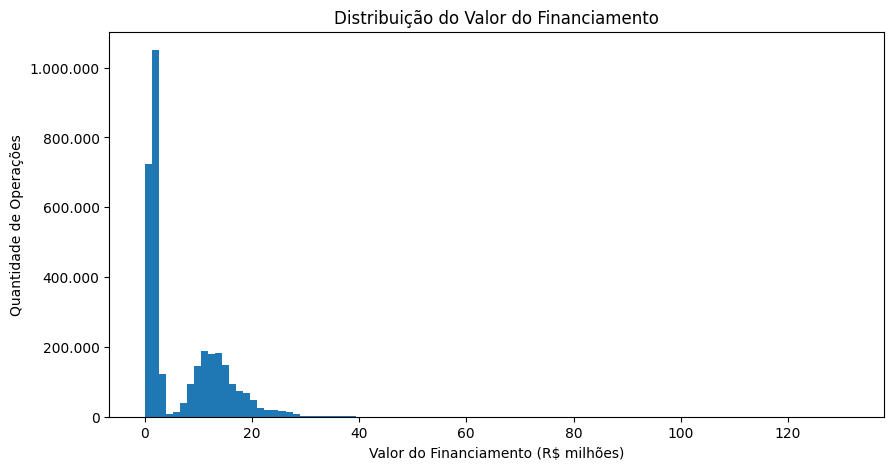

In [9]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

plt.figure(figsize=(10,5))

plt.hist(
    df["vlr_financiamento"] / 1_000_000,
    bins=100
)

plt.ylabel("Quantidade de Operações")
plt.xlabel("Valor do Financiamento (R$ milhões)")
plt.title("Distribuição do Valor do Financiamento")

formatter = FuncFormatter(
    lambda x, p: f"{int(x):,}".replace(",", ".")
)

plt.gca().yaxis.set_major_formatter(formatter)

plt.show()

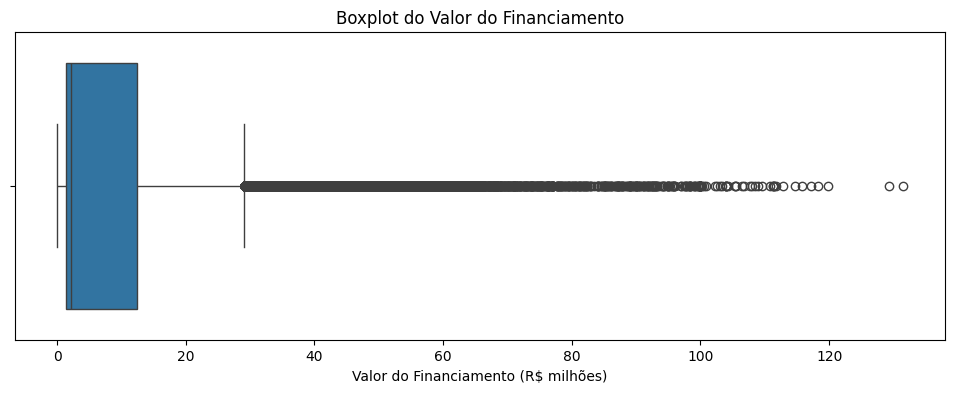

In [10]:
import seaborn as sns

plt.figure(figsize=(12,4))

sns.boxplot(
    x=df["vlr_financiamento"] / 1_000_000
)

plt.xlabel("Valor do Financiamento (R$ milhões)")
plt.title("Boxplot do Valor do Financiamento")

plt.show()

### Análise de valores extremos

O boxplot identificou grande quantidade de observações classificadas como valores extremos segundo a regra do intervalo interquartil (IQR).

Entretanto, a simples classificação estatística como outlier não implica necessariamente erro ou inconsistência nos dados.

Considerando a natureza das operações habitacionais presentes na base, valores elevados podem representar contratos legítimos de maior porte.

Por esse motivo, nenhuma remoção de registros será realizada nesta etapa. A avaliação dos impactos desses valores será considerada posteriormente durante a modelagem.

In [11]:
(df["vlr_financiamento"] == 0).sum()


np.int64(674)

In [12]:

(df["vlr_financiamento"] == 0).mean() * 100

np.float64(0.020494607242441475)

### Conclusões sobre a distribuição da variável-alvo

A análise da variável-alvo revelou forte assimetria positiva, com concentração da maior parte das operações em valores relativamente menores e presença de uma longa cauda de financiamentos de maior valor.

A média observada foi significativamente superior à mediana, indicando influência de operações com valores elevados.

Os gráficos evidenciaram a existência de valores extremos sob a ótica estatística. Entretanto, devido à natureza do domínio analisado, esses registros não serão considerados automaticamente inconsistentes.

Também foram identificadas 674 operações com valor igual a zero, representando aproximadamente 0,02% da base, percentual considerado pouco representativo neste estágio da análise.

Os resultados sugerem que a variável apresenta distribuição não normal e elevada dispersão, características que deverão ser consideradas durante a modelagem.

## 3.6 Relação entre renda familiar e valor financiado

A renda familiar representa uma das principais variáveis econômicas disponíveis na base e potencialmente uma das mais relevantes para explicar o valor financiado.

Espera-se que famílias com maior capacidade financeira tenham acesso a operações de maior valor, embora outros fatores também possam influenciar essa relação, como localização, programa habitacional, subsídios e características do imóvel.

Nesta seção serão avaliados:

- distribuição da renda familiar;
- presença de valores extremos;
- relação entre renda familiar e valor financiado;
- evidências iniciais de capacidade explicativa da variável.

Os resultados obtidos poderão contribuir para a seleção das variáveis utilizadas nos modelos de regressão.

In [13]:
df["vlr_renda_familiar"] = (
    df["vlr_renda_familiar"]
    .astype(str)
    .str.replace(".", "", regex=False)
    .str.replace(",", ".", regex=False)
    .astype(float)
)

df["vlr_renda_familiar"].describe()

count    3.288670e+06
mean     2.881654e+05
std      3.217768e+05
min      0.000000e+00
25%      3.920000e+04
50%      2.361075e+05
75%      4.067310e+05
max      4.757644e+07
Name: vlr_renda_familiar, dtype: float64

In [14]:
df["vlr_renda_familiar"].quantile(
    [0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
)

0.01      16335.00
0.05      20000.00
0.25      39200.00
0.50     236107.50
0.75     406731.00
0.95     773681.00
0.99    1199814.93
Name: vlr_renda_familiar, dtype: float64

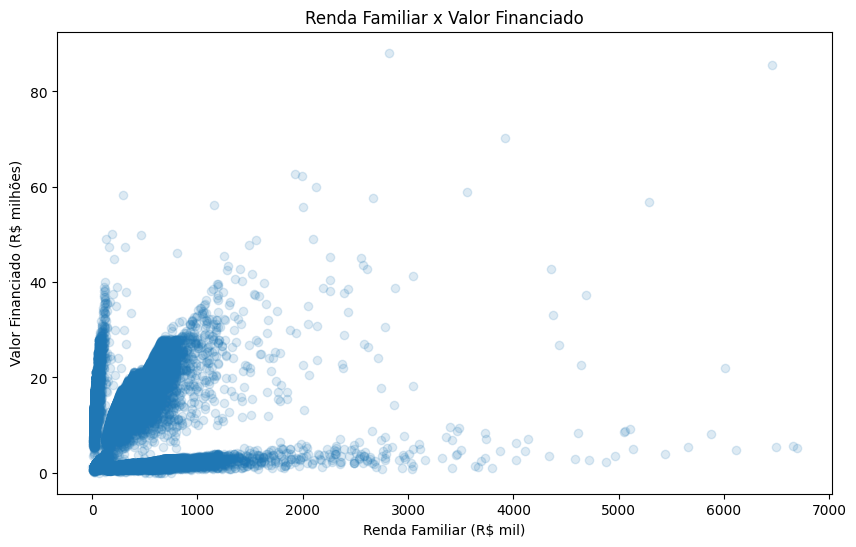

In [15]:
amostra = df.sample(
    n=50000,
    random_state=42
)

plt.figure(figsize=(10,6))

plt.scatter(
    amostra["vlr_renda_familiar"] / 1000,
    amostra["vlr_financiamento"] / 1_000_000,
    alpha=0.15
)

plt.xlabel("Renda Familiar (R$ mil)")
plt.ylabel("Valor Financiado (R$ milhões)")
plt.title("Renda Familiar x Valor Financiado")

plt.show()

### 3.6.1 Relação entre renda familiar e valor financiado

O gráfico de dispersão permite visualizar como o valor financiado se comporta em relação à renda familiar declarada.

Em geral, observa-se uma tendência positiva entre as variáveis, indicando que operações associadas a rendas mais elevadas tendem a apresentar financiamentos de maior valor.

Entretanto, a dispersão observada sugere que a renda familiar não é o único fator determinante do valor financiado, indicando que outras características da operação também exercem influência relevante.

## 3.7 Análise dos Programas Habitacionais

A base contempla diferentes programas e modalidades de financiamento habitacional, cada um com regras, públicos-alvo e características operacionais específicas.

Considerando que essas modalidades podem influenciar diretamente o valor financiado, torna-se importante avaliar a distribuição dos programas presentes na base e suas possíveis diferenças em relação à variável-alvo.

Além disso, esta análise permite identificar inconsistências de padronização que poderão demandar tratamento durante a etapa de pré-processamento.

O objetivo desta seção é investigar se o programa habitacional representa uma variável potencialmente relevante para os modelos preditivos.

In [16]:
programas_freq = (
    df["txt_programa_fgts"]
    .value_counts()
    .to_frame("quantidade")
)

programas_freq["percentual"] = (
    programas_freq["quantidade"] / len(df) * 100
).round(2)

display(programas_freq)

,quantidade,percentual
txt_programa_fgts,,
Apoio à Produção,1407037,42.78
Carta de Crédito - Individual,1343559,40.85
Apoio à producao,163346,4.97
Carta de crédito Individual,137075,4.17
Fundo Social,127594,3.88
Pró-Cotista,80130,2.44
Classe Média,27406,0.83
Pró-Cotista - PF - Urbano,916,0.03
Pró-Cotista - PF - PMCMV,724,0.02


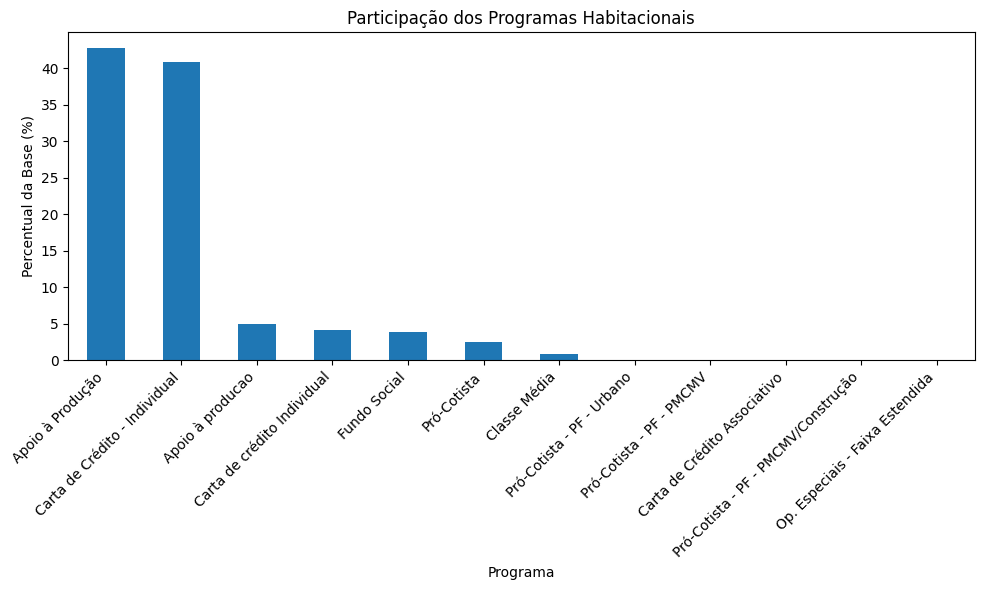

In [17]:
plt.figure(figsize=(10,6))

programas_freq["percentual"].plot.bar()

plt.title("Participação dos Programas Habitacionais")
plt.ylabel("Percentual da Base (%)")
plt.xlabel("Programa")

plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

In [18]:
programa_mediana = (
    df.groupby("txt_programa_fgts")["vlr_financiamento"]
      .median()
      .sort_values(ascending=False)
      / 1_000_000
)

display(programa_mediana)


txt_programa_fgts
Apoio à producao                       12.093666
Carta de Crédito Associativo            9.152111
Apoio à Produção                        8.890411
Pró-Cotista - PF - PMCMV/Construção     4.127500
Pró-Cotista - PF - Urbano               3.600000
Classe Média                            2.934500
Pró-Cotista - PF - PMCMV                2.900000
Pró-Cotista                             2.800000
Fundo Social                            2.240000
Carta de crédito Individual             1.808000
Op. Especiais - Faixa Estendida         1.742400
Carta de Crédito - Individual           1.560000
Name: vlr_financiamento, dtype: float64

### Principais achados da análise dos programas habitacionais

A análise revelou forte concentração das operações em dois programas principais: Apoio à Produção e Carta de Crédito - Individual, que juntos representam aproximadamente 84% dos registros da base.

Também foram identificadas inconsistências de padronização textual em algumas categorias, indicando necessidade de tratamento durante a etapa de pré-processamento. Foram observadas diferenças de grafia e acentuação em programas aparentemente equivalentes.

Além da diferença de participação na base, os programas apresentaram valores financiados substancialmente distintos. Programas associados ao Apoio à Produção apresentaram medianas de financiamento significativamente superiores às observadas nas modalidades individuais de crédito.

Os resultados sugerem que o programa habitacional possui elevada capacidade explicativa em relação ao valor financiado e deverá ser considerado entre as variáveis candidatas para os modelos preditivos.

## 3.8 Análise Geográfica das Operações

A base contém informações geográficas associadas às operações habitacionais, incluindo município, unidade federativa e região.

Aspectos regionais podem influenciar diretamente o valor financiado, refletindo diferenças econômicas, demográficas e imobiliárias entre localidades brasileiras.

Nesta seção serão analisadas a distribuição geográfica das operações e possíveis diferenças nos valores financiados entre regiões.

In [19]:
regioes = (
    df["txt_regiao"]
    .value_counts()
    .to_frame("quantidade")
)

regioes["percentual"] = (
    regioes["quantidade"] / len(df) * 100
).round(2)

display(regioes)

,quantidade,percentual
txt_regiao,,
SUDESTE,1562709,47.52
NORDESTE,661746,20.12
SUL,588436,17.89
CENTRO-OESTE,382770,11.64
NORTE,93007,2.83


### Distribuição regional das operações

A distribuição das operações habitacionais não ocorre de forma homogênea entre as regiões brasileiras.

Observou-se forte concentração de registros na região Sudeste, responsável por aproximadamente metade das operações presentes na base.

As regiões Sudeste, Nordeste e Sul concentram a maior parte dos registros analisados, enquanto a região Norte apresenta participação significativamente menor.

Essa distribuição sugere que características regionais poderão influenciar o comportamento do modelo e devem ser consideradas durante a interpretação dos resultados.

In [20]:
regiao_financiamento = (
    df.groupby("txt_regiao")["vlr_financiamento"]
      .agg(["count", "mean", "median"])
      .sort_values("median", ascending=False)
)

regiao_financiamento

,count,mean,median
txt_regiao,,,
SUDESTE,1562709,7.782656e+06,2582941.0
CENTRO-OESTE,382770,6.164921e+06,2076000.0
SUL,588436,6.006992e+06,1951200.0
NORDESTE,661746,6.184641e+06,1760000.0
NORTE,93007,5.785021e+06,1725673.0


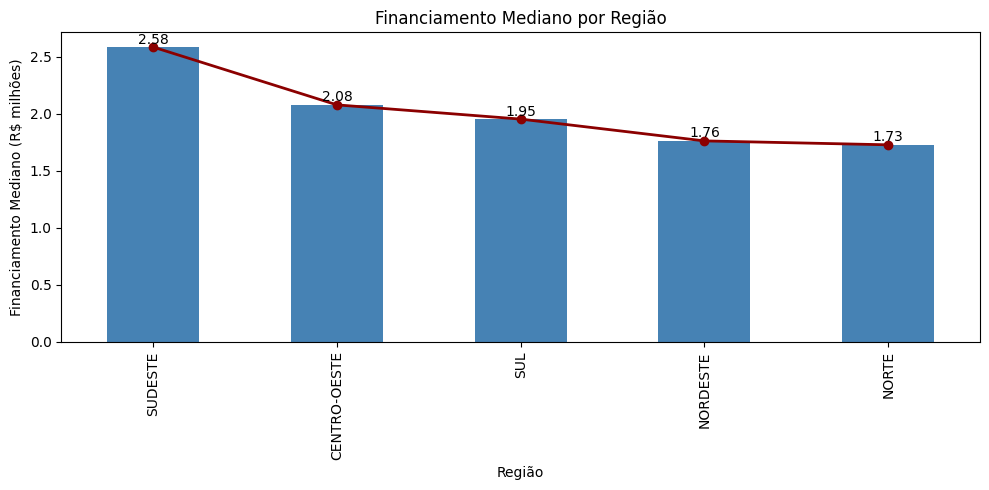

In [21]:
regiao_mediana = (
    df.groupby("txt_regiao")["vlr_financiamento"]
      .median()
      .sort_values(ascending=False)
      / 1_000_000
)

ax = regiao_mediana.plot(
    kind="bar",
    figsize=(10,5),
    color="steelblue"
)

plt.plot(
    range(len(regiao_mediana)),
    regiao_mediana.values,
    color="darkred",
    marker="o",
    linewidth=2
)

for i, v in enumerate(regiao_mediana.values):
    plt.text(
        i,
        v + 0.03,
        f"{v:,.2f}",
        ha="center"
    )

plt.title("Financiamento Mediano por Região")
plt.ylabel("Financiamento Mediano (R$ milhões)")
plt.xlabel("Região")

plt.tight_layout()
plt.show()


### Principais achados da análise geográfica

A análise revelou forte concentração das operações habitacionais na região Sudeste, responsável por aproximadamente metade dos registros presentes na base analisada.

Também foram observadas diferenças relevantes nos valores financiados entre as regiões brasileiras. A região Sudeste apresentou o maior valor mediano financiado, seguida pelas regiões Centro-Oeste e Sul, enquanto Norte e Nordeste apresentaram medianas inferiores.

Esses resultados indicam que fatores geográficos podem exercer influência sobre o valor financiado, sugerindo que variáveis relacionadas à localização deverão ser consideradas nas etapas posteriores de modelagem.

Além disso, a concentração geográfica observada evidencia que determinadas regiões possuem maior representatividade no conjunto de dados, aspecto que deverá ser levado em consideração na interpretação dos resultados e no desempenho dos modelos preditivos.

## 3.9 Principais Achados da Análise Exploratória

A análise exploratória permitiu identificar características importantes da base e potenciais fatores associados ao valor do financiamento habitacional.

Os principais resultados observados foram:

- A base apresenta elevada qualidade de dados, com baixo percentual de valores ausentes na maior parte das variáveis. A exceção foi a variável `bln_cotista`, que apresentou mais de 80% de ausência e se tornou candidata à exclusão nas etapas posteriores.

- A variável-alvo `vlr_financiamento` apresentou forte assimetria positiva, elevada dispersão e presença de valores extremos. A média observada foi significativamente superior à mediana, indicando a existência de operações de maior valor que deslocam a distribuição para a direita.

- Foram identificadas operações com valor de financiamento igual a zero, porém sua representatividade é extremamente reduzida na base analisada.

- A renda familiar apresentou comportamento semelhante ao observado para o valor financiado, com forte dispersão e presença de valores elevados. A análise gráfica indicou associação positiva entre renda familiar e valor financiado.

- Os programas habitacionais apresentaram diferenças relevantes quanto ao perfil financeiro das operações. Programas relacionados ao Apoio à Produção apresentaram valores financiados medianos superiores aos observados em modalidades de crédito individual.

- Foram identificadas inconsistências de padronização em categorias da variável `txt_programa_fgts`, indicando necessidade de tratamento durante o pré-processamento.

- A análise geográfica revelou forte concentração das operações na região Sudeste, responsável por aproximadamente metade dos registros da base.

- Também foram observadas diferenças regionais nos valores financiados, sugerindo que informações geográficas possuem potencial explicativo para a previsão do valor do financiamento.

De forma geral, os resultados indicam que variáveis econômicas, geográficas e relacionadas à modalidade da operação possuem potencial para explicar parte significativa da variabilidade observada no valor financiado.

Esses achados servirão como base para a definição das estratégias de pré-processamento, seleção de atributos e construção dos modelos de Machine Learning.

# 4. Pré-processamento dos Dados

Com base nos resultados da análise exploratória, serão realizadas as transformações necessárias para preparar os dados para a etapa de modelagem.

As decisões adotadas nesta etapa são fundamentadas nos achados da EDA e buscam garantir consistência dos dados, reduzir ruídos e tornar as variáveis adequadas para utilização pelos algoritmos de Machine Learning.

As principais atividades incluem:

- seleção das variáveis;
- tratamento de valores ausentes;
- padronização de categorias;
- transformação de variáveis;
- preparação das variáveis categóricas;
- definição das features utilizadas pelos modelos.

## 4.1 Seleção Inicial das Variáveis

Com base nos resultados da análise exploratória, foi realizada uma avaliação inicial das variáveis disponíveis na base.

Nesta etapa são definidas as variáveis que deverão ser mantidas, removidas ou transformadas durante o pré-processamento.

As decisões adotadas foram fundamentadas em critérios como:

- percentual de valores ausentes;
- potencial poder explicativo;
- qualidade dos dados;
- relevância para o problema de negócio;
- disponibilidade da informação no momento da previsão.

In [22]:
decisoes = pd.DataFrame({
    "variavel": df.columns
})

display(decisoes)

,variavel
0,data_referencia
1,cod_ibge
2,txt_municipio
3,mcmv_fgts_txt_uf
4,txt_regiao
5,data_assinatura_financiamento
6,qtd_uh_financiadas
7,vlr_financiamento
8,vlr_subsidio_desconto_fgts
9,vlr_subsidio_desconto_ogu


In [23]:
df["data_referencia"].nunique()

1

In [24]:
df["data_referencia"].value_counts(dropna=False)

data_referencia
24/07/2026    3288670
Name: count, dtype: int64

In [25]:
df["bln_cotista"].value_counts(dropna=False)

bln_cotista
NaN    2846028
S       175891
N       139157
1        97147
0        30447
Name: count, dtype: int64

In [26]:
df["data_assinatura_financiamento"].dt.year.value_counts().sort_index()


data_assinatura_financiamento
2020    387902
2021    353444
2022    383367
2023    491209
2024    605554
2025    668553
2026    398641
Name: count, dtype: int64

## 4.1.1 Decisões Iniciais de Pré-processamento

Com base nos resultados da análise exploratória, foi realizada uma avaliação inicial das variáveis disponíveis na base.

As decisões adotadas nesta etapa foram fundamentadas em critérios como:

- qualidade dos dados;
- percentual de valores ausentes;
- relevância para o problema de negócio;
- potencial capacidade explicativa para a variável-alvo;
- disponibilidade da informação no momento da previsão.

O objetivo desta etapa é definir quais variáveis serão removidas, mantidas ou transformadas antes da construção dos modelos de Machine Learning.

### Variáveis removidas

| Variável | Justificativa |
|-----------|-----------|
| `data_referencia` | Apresentou apenas um único valor em toda a base analisada, não fornecendo informação útil para diferenciação entre observações. |
| `bln_cotista` | Apresentou aproximadamente 86,5% de valores ausentes e inconsistências de representação, com registros contendo simultaneamente os valores "S", "N", "1" e "0". |

### Variáveis transformadas

| Variável | Transformação planejada |
|-----------|-----------|
| `data_assinatura_financiamento` | Extração de atributos temporais como ano, mês e trimestre da contratação. |
| `txt_programa_fgts` | Padronização das categorias devido às inconsistências identificadas durante a EDA. |
| Variáveis monetárias | Conversão para formato numérico adequado para modelagem. |

### Variáveis mantidas

As variáveis abaixo permanecerão disponíveis para as etapas posteriores de preparação dos dados e seleção de atributos.

#### Informações geográficas

- `cod_ibge`
- `txt_municipio`
- `mcmv_fgts_txt_uf`
- `txt_regiao`

A análise geográfica identificou diferenças relevantes entre regiões brasileiras e valores financiados distintos entre elas, indicando potencial influência da localização sobre a variável-alvo.

#### Informações temporais

- `data_assinatura_financiamento`

A distribuição das operações variou ao longo dos anos analisados, indicando potencial capacidade explicativa de atributos temporais derivados da data de contratação.

#### Informações financeiras

- `vlr_subsidio_desconto_fgts`
- `vlr_subsidio_desconto_ogu`
- `vlr_subsidio_equilíbrio_fgts`
- `vlr_subsidio_equilíbrio_ogu`
- `vlr_compra`
- `vlr_renda_familiar`
- `num_taxa_juros`

Essas variáveis estão diretamente relacionadas às características econômicas da operação e apresentam forte potencial explicativo para o valor financiado.

#### Informações da operação

- `qtd_uh_financiadas`
- `txt_programa_fgts`
- `txt_tipo_imovel`
- `txt_sistema_amortizacao`
- `txt_compatibilidade_faixa_renda`

A análise exploratória identificou diferenças relevantes entre programas habitacionais e modalidades de financiamento, sugerindo influência dessas variáveis sobre a variável-alvo.

#### Informações do beneficiário

- `co_sexo`

A variável apresentou baixo percentual de valores ausentes e será mantida para avaliação durante a modelagem.

### Variável-alvo

A variável-alvo do projeto permanece definida como:

- `vlr_financiamento`

O objetivo dos modelos será estimar o valor financiado das operações habitacionais a partir das características socioeconômicas, geográficas, temporais e financeiras disponíveis.

### Síntese das decisões

Ao final desta etapa foram definidas as seguintes ações iniciais:

- remoção de variáveis sem poder informativo ou com elevado percentual de ausência;
- transformação de variáveis temporais;
- padronização de categorias inconsistentes;
- conversão de variáveis monetárias para formato numérico;
- manutenção das variáveis consideradas relevantes segundo os resultados da análise exploratória.

Essas decisões foram fundamentadas nos achados identificados durante a EDA e servirão como base para as próximas etapas de preparação dos dados e modelagem.

## 4.2 Tratamento das Variáveis Temporais

A variável `data_assinatura_financiamento` foi mantida na etapa de seleção de atributos por apresentar variabilidade ao longo de todo o período analisado.

Entretanto, datas completas raramente são utilizadas diretamente pelos algoritmos de Machine Learning. Em vez disso, é comum extrair atributos temporais capazes de representar padrões sazonais e mudanças observadas ao longo do tempo.

Com base nessa estratégia, serão criadas variáveis derivadas representando o ano, o mês e o trimestre da contratação.

Essas novas variáveis poderão capturar efeitos temporais sobre o comportamento dos financiamentos habitacionais e serão avaliadas posteriormente durante a modelagem.

In [27]:
df["ano_contratacao"] = (
    df["data_assinatura_financiamento"].dt.year
)

df["mes_contratacao"] = (
    df["data_assinatura_financiamento"].dt.month
)

df["trimestre_contratacao"] = (
    df["data_assinatura_financiamento"].dt.quarter
)

df[
    [
        "data_assinatura_financiamento",
        "ano_contratacao",
        "mes_contratacao",
        "trimestre_contratacao"
    ]
].head()

,data_assinatura_financiamento,ano_contratacao,mes_contratacao,trimestre_contratacao
0,2026-02-20,2026,2,1
1,2026-03-06,2026,3,1
2,2026-06-24,2026,6,2
3,2026-05-13,2026,5,2
4,2026-05-12,2026,5,2


### Resultado da transformação temporal

A partir da variável `data_assinatura_financiamento` foram criados os atributos:

- `ano_contratacao`
- `mes_contratacao`
- `trimestre_contratacao`

Essas variáveis serão avaliadas como potenciais atributos explicativos durante a etapa de modelagem.

## 4.3 Padronização das Categorias

A análise exploratória identificou inconsistências de padronização na variável `txt_programa_fgts`.

Foram observadas categorias que aparentam representar a mesma modalidade de financiamento, mas que diferem em aspectos de grafia e acentuação.

A padronização dessas categorias busca reduzir redundâncias e melhorar a qualidade das variáveis utilizadas pelos modelos.

### 4.3.1 Padronização da variável `txt_programa_fgts`

Durante a análise exploratória foram identificadas categorias semanticamente equivalentes que diferiam apenas por grafia, capitalização ou acentuação.

Essas categorias foram consolidadas para reduzir redundâncias e evitar que registros equivalentes fossem tratados como grupos distintos pelos algoritmos de Machine Learning.

In [28]:
mapeamento_programas = {
    "Apoio à producao": "Apoio à Produção",
    "Carta de crédito Individual": "Carta de Crédito Individual",
    "Carta de Crédito - Individual": "Carta de Crédito Individual"
}

df["txt_programa_fgts"] = (
    df["txt_programa_fgts"]
    .replace(mapeamento_programas)
)

df["txt_programa_fgts"].value_counts()

txt_programa_fgts
Apoio à Produção                       1570383
Carta de Crédito Individual            1480634
Fundo Social                            127594
Pró-Cotista                              80130
Classe Média                             27406
Pró-Cotista - PF - Urbano                  916
Pró-Cotista - PF - PMCMV                   724
Carta de Crédito Associativo               647
Pró-Cotista - PF - PMCMV/Construção        132
Op. Especiais - Faixa Estendida            104
Name: count, dtype: int64

### Resultado da padronização

Após a consolidação das categorias equivalentes, foram eliminadas redundâncias decorrentes de diferenças de grafia, capitalização e acentuação.

A padronização reduziu a quantidade de categorias distintas semanticamente equivalentes e aumentou a consistência da variável `txt_programa_fgts`.

Essa transformação contribui para que os modelos interpretem corretamente programas habitacionais equivalentes, evitando fragmentação artificial dos dados.

## 4.4 Tratamento dos Valores Ausentes

A análise exploratória identificou baixo percentual de valores ausentes na maior parte das variáveis mantidas para modelagem.

Em vez da remoção de registros, será adotada uma estratégia de preservação das observações, reduzindo a perda de informação disponível na base.

O tratamento aplicado dependerá da natureza de cada variável e da proporção de valores ausentes observada.

In [29]:
for col in [
    "txt_sistema_amortizacao",
    "txt_compatibilidade_faixa_renda",
    "co_sexo"
]:
    print("\n" + "=" * 80)
    print(col)
    print("=" * 80)
    print(df[col].value_counts(dropna=False))


txt_sistema_amortizacao
txt_sistema_amortizacao
price    2855799
sac       265085
PRICE     110046
NaN        40192
SAC        17548
Name: count, dtype: int64

txt_compatibilidade_faixa_renda
txt_compatibilidade_faixa_renda
2.0    1297783
1.0     960298
3.0     883484
NaN      91795
4.0      55310
Name: count, dtype: int64

co_sexo
co_sexo
M      1728096
F      1539763
NaN      19517
X         1294
Name: count, dtype: int64


### 4.4.1 Tratamento das Variáveis Categóricas com Valores Ausentes

As variáveis categóricas remanescentes apresentaram baixo percentual de valores ausentes.

Optou-se por preservar as observações e criar uma categoria específica para representar informações não disponíveis, evitando a exclusão de registros e permitindo que os modelos avaliem se a ausência da informação possui comportamento próprio.

In [30]:
df["txt_sistema_amortizacao"] = (
    df["txt_sistema_amortizacao"]
    .str.upper()
    .fillna("NAO_INFORMADO")
)

df["txt_sistema_amortizacao"].value_counts()

txt_sistema_amortizacao
PRICE            2965845
SAC               282633
NAO_INFORMADO      40192
Name: count, dtype: int64

### Tratamento aplicado à variável `txt_sistema_amortizacao`

A variável apresentava inconsistências de capitalização, com categorias equivalentes representadas de formas distintas.

Inicialmente foi realizada a padronização textual das categorias, consolidando registros semanticamente equivalentes.

Posteriormente, os valores ausentes foram substituídos pela categoria `NAO_INFORMADO`, preservando os registros da base e permitindo que os modelos avaliem eventual comportamento específico associado à ausência da informação.

Após o tratamento, a variável passou a conter apenas três categorias:

- PRICE
- SAC
- NAO_INFORMADO

In [31]:
df["txt_compatibilidade_faixa_renda"] = (
    df["txt_compatibilidade_faixa_renda"]
    .fillna("NAO_INFORMADO")
)

df["txt_compatibilidade_faixa_renda"].value_counts(dropna=False)

txt_compatibilidade_faixa_renda
2.0              1297783
1.0               960298
3.0               883484
NAO_INFORMADO      91795
4.0                55310
Name: count, dtype: int64

### Tratamento aplicado à variável `txt_compatibilidade_faixa_renda`

A variável representa a compatibilidade da operação com as faixas de renda do Programa Minha Casa Minha Vida.

Por se tratar de uma informação diretamente relacionada ao enquadramento da operação habitacional, a variável foi mantida para utilização posterior nos modelos.

Os registros sem informação disponível foram agrupados na categoria `NAO_INFORMADO`, permitindo preservar as observações da base sem introduzir imputações artificiais.

Essa abordagem reduz a perda de informação e permite que os modelos avaliem se a ausência do dado possui comportamento próprio.

In [32]:
df["co_sexo"] = (
    df["co_sexo"]
    .fillna("NAO_INFORMADO")
)

df["co_sexo"].value_counts(dropna=False)

co_sexo
M                1728096
F                1539763
NAO_INFORMADO      19517
X                   1294
Name: count, dtype: int64

### Tratamento aplicado à variável `co_sexo`

A variável apresentou baixo percentual de valores ausentes em relação ao volume total da base.

Os registros sem informação disponível foram agrupados na categoria `NAO_INFORMADO`, permitindo preservar as observações e evitar perda desnecessária de dados.

As categorias originais observadas na base foram mantidas, uma vez que não foram identificadas evidências que justificassem sua alteração ou agrupamento.

Após o tratamento, a variável passou a conter as categorias:

- M
- F
- X
- NAO_INFORMADO

### Tratamento dos valores ausentes em variáveis numéricas

A análise identificou quantidade residual de valores ausentes em algumas variáveis numéricas.

Nas variáveis relacionadas aos subsídios de equilíbrio (`vlr_subsidio_equilíbrio_fgts` e `vlr_subsidio_equilíbrio_ogu`), os valores ausentes foram substituídos por zero, assumindo que a ausência da informação representa inexistência do benefício correspondente.

Para os casos isolados observados em `cod_ibge` e `vlr_compra`, foram utilizadas estratégias simples de imputação, uma vez que a quantidade de registros afetados é irrelevante em relação ao volume total da base.

In [33]:
df["vlr_subsidio_equilíbrio_fgts"] = (
    df["vlr_subsidio_equilíbrio_fgts"]
    .fillna(0)
)

df["vlr_subsidio_equilíbrio_ogu"] = (
    df["vlr_subsidio_equilíbrio_ogu"]
    .fillna(0)
)

df["cod_ibge"] = (
    df["cod_ibge"]
    .fillna(df["cod_ibge"].mode()[0])
)

df["vlr_compra"] = (
    df["vlr_compra"]
    .fillna(df["vlr_compra"].median())
)

## 4.5 Preparação do Dataset para Modelagem

Após as etapas de limpeza e padronização, será preparado o conjunto de dados utilizado no treinamento e avaliação dos modelos.

Nesta etapa serão definidas:

- as variáveis utilizadas como atributos preditivos;
- a variável-alvo;
- a divisão entre conjuntos de treino e teste;
- a estrutura utilizada pelos algoritmos de Machine Learning.

A preparação será realizada de forma a evitar vazamento de informações e permitir avaliação adequada da capacidade de generalização dos modelos.

In [34]:
df.dtypes

data_referencia                            object
cod_ibge                                  float64
txt_municipio                              object
mcmv_fgts_txt_uf                           object
txt_regiao                                 object
data_assinatura_financiamento      datetime64[ns]
qtd_uh_financiadas                          int64
vlr_financiamento                         float64
vlr_subsidio_desconto_fgts                float64
vlr_subsidio_desconto_ogu                 float64
vlr_subsidio_equilíbrio_fgts              float64
vlr_subsidio_equilíbrio_ogu               float64
vlr_compra                                float64
vlr_renda_familiar                        float64
txt_programa_fgts                          object
num_taxa_juros                            float64
txt_tipo_imovel                            object
bln_cotista                                object
txt_sistema_amortizacao                    object
txt_compatibilidade_faixa_renda            object


## 4.5.1 Definição das Variáveis de Modelagem

Com base nas etapas anteriores de preparação dos dados, foi definido o conjunto inicial de variáveis candidatas para utilização nos modelos preditivos.

As variáveis removidas durante o pré-processamento não serão consideradas nas etapas subsequentes de treinamento e avaliação.

In [35]:
features = [
    "cod_ibge",
    "txt_municipio",
    "mcmv_fgts_txt_uf",
    "txt_regiao",
    "qtd_uh_financiadas",
    "vlr_subsidio_desconto_fgts",
    "vlr_subsidio_desconto_ogu",
    "vlr_subsidio_equilíbrio_fgts",
    "vlr_subsidio_equilíbrio_ogu",
    "vlr_compra",
    "vlr_renda_familiar",
    "txt_programa_fgts",
    "num_taxa_juros",
    "txt_tipo_imovel",
    "txt_sistema_amortizacao",
    "txt_compatibilidade_faixa_renda",
    "co_sexo",
    "ano_contratacao",
    "mes_contratacao",
    "trimestre_contratacao"
]

target = "vlr_financiamento"

print("Quantidade de features:", len(features))
print("Target:", target)

Quantidade de features: 20
Target: vlr_financiamento


In [36]:
colunas_categoricas = [
    "txt_municipio",
    "mcmv_fgts_txt_uf",
    "txt_regiao",
    "txt_programa_fgts",
    "txt_tipo_imovel",
    "txt_sistema_amortizacao",
    "txt_compatibilidade_faixa_renda",
    "co_sexo"
]

for col in colunas_categoricas:
    df[col] = df[col].fillna("NAO_INFORMADO").astype(str)

## 4.5.2 Avaliação Inicial de Potencial Vazamento

Antes da construção dos modelos, foi realizada uma avaliação preliminar das variáveis financeiras disponíveis na base.

O objetivo desta etapa é identificar possíveis situações de vazamento de informação (data leakage), nas quais uma variável contenha informação excessivamente próxima da variável-alvo.

Variáveis com correlação extremamente elevada ou que representem diretamente o resultado da operação podem gerar estimativas artificialmente otimistas e comprometer a avaliação real dos modelos.

In [37]:
cols_numericas = [
    "vlr_financiamento",
    "vlr_compra",
    "vlr_renda_familiar",
    "vlr_subsidio_desconto_fgts",
    "vlr_subsidio_desconto_ogu",
    "vlr_subsidio_equilíbrio_fgts",
    "vlr_subsidio_equilíbrio_ogu",
    "num_taxa_juros",
    "qtd_uh_financiadas"
]

corr = df[cols_numericas].corr()

corr["vlr_financiamento"].sort_values(
    ascending=False
)

vlr_financiamento               1.000000
vlr_compra                      0.253030
vlr_subsidio_desconto_fgts      0.053327
vlr_subsidio_equilíbrio_fgts    0.040066
vlr_renda_familiar              0.019859
num_taxa_juros                 -0.001952
vlr_subsidio_desconto_ogu      -0.027089
vlr_subsidio_equilíbrio_ogu    -0.044213
qtd_uh_financiadas                   NaN
Name: vlr_financiamento, dtype: float64

### Definição do conjunto inicial de modelagem

Após as etapas de limpeza, padronização e transformação dos dados, foi definido o conjunto inicial de atributos utilizado para treinamento e avaliação dos modelos.

Também foi realizada uma avaliação preliminar das variáveis financeiras com o objetivo de identificar possíveis situações de vazamento de informação.

As correlações observadas não indicaram evidências de relação linear excessivamente forte entre as variáveis explicativas avaliadas e a variável-alvo.

Assim, as variáveis selecionadas foram mantidas para utilização na etapa inicial de modelagem.

In [38]:
from sklearn.model_selection import train_test_split

X = df[features].copy()
y = df[target].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Treino:", X_train.shape)
print("Teste :", X_test.shape)

Treino: (2630936, 20)
Teste : (657734, 20)


# 5. Modelagem

Após a preparação dos dados e definição dos conjuntos de treino e teste, serão construídos e comparados diferentes modelos de regressão.

Conforme recomendado pelas boas práticas de Machine Learning, a avaliação será iniciada por um modelo de referência simples (baseline), que servirá como parâmetro mínimo de desempenho para os modelos mais sofisticados.

Os modelos serão avaliados utilizando métricas apropriadas para problemas de regressão e comparados quanto à sua capacidade de generalização.

## 5.1 Modelo de Referência (Baseline)

Como primeira referência de desempenho será utilizado um modelo baseline.

O objetivo do baseline é estabelecer um ponto mínimo de comparação para os modelos mais sofisticados.

Neste projeto será utilizado o `DummyRegressor`, que prevê sempre o mesmo valor para todas as observações, correspondente à média observada no conjunto de treino.

Qualquer modelo considerado útil deverá apresentar desempenho superior ao baseline.

In [39]:
import numpy as np

from sklearn.dummy import DummyRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Baseline
dummy = DummyRegressor(strategy="mean")

dummy.fit(
    X_train.select_dtypes(include=["number"]),
    y_train
)

# Previsões
pred_dummy = dummy.predict(
    X_test.select_dtypes(include=["number"])
)

# Métricas
mae_dummy = mean_absolute_error(
    y_test,
    pred_dummy
)

rmse_dummy = np.sqrt(
    mean_squared_error(
        y_test,
        pred_dummy
    )
)

r2_dummy = r2_score(
    y_test,
    pred_dummy
)

# Resultados
print("RESULTADOS - BASELINE (DummyRegressor)")
print("-" * 50)
print(f"MAE : {mae_dummy:,.2f}")
print(f"RMSE: {rmse_dummy:,.2f}")
print(f"R²  : {r2_dummy:.4f}")

RESULTADOS - BASELINE (DummyRegressor)
--------------------------------------------------
MAE : 6,175,137.97
RMSE: 7,060,576.91
R²  : -0.0000


### Resultado do modelo baseline

O modelo de referência (`DummyRegressor`) foi utilizado para estabelecer um desempenho mínimo de comparação para os modelos subsequentes.

Como esperado, o modelo apresentou capacidade preditiva extremamente limitada, uma vez que realiza previsões constantes baseadas apenas na média observada no conjunto de treinamento.

Os resultados obtidos foram:

- MAE: R$ 6.175.137,97
- RMSE: R$ 7.060.576,91
- R²: aproximadamente 0

Esses resultados servirão como referência para avaliar se os modelos mais sofisticados conseguem extrair informações úteis das variáveis explicativas e produzir previsões superiores à simples utilização da média histórica.

## 5.2 Regressão Linear

In [40]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LinearRegression

colunas_numericas = X_train.select_dtypes(
    include=["number"]
).columns

colunas_categoricas = X_train.select_dtypes(
    include=["object"]
).columns

preprocessador = ColumnTransformer(
    transformers=[
        (
            "num",
            "passthrough",
            colunas_numericas
        ),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            colunas_categoricas
        )
    ]
)

modelo_linear = Pipeline(
    steps=[
        ("preprocessamento", preprocessador),
        ("modelo", LinearRegression())
    ]
)

modelo_linear.fit(
    X_train,
    y_train
)

pred_linear = modelo_linear.predict(
    X_test
)

print("Modelo treinado com sucesso!")

Modelo treinado com sucesso!


In [41]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import numpy as np

mae_linear = mean_absolute_error(
    y_test,
    pred_linear
)

rmse_linear = np.sqrt(
    mean_squared_error(
        y_test,
        pred_linear
    )
)

r2_linear = r2_score(
    y_test,
    pred_linear
)

print("RESULTADOS - REGRESSÃO LINEAR")
print("-" * 50)
print(f"MAE : {mae_linear:,.2f}")
print(f"RMSE: {rmse_linear:,.2f}")
print(f"R²  : {r2_linear:.4f}")

RESULTADOS - REGRESSÃO LINEAR
--------------------------------------------------
MAE : 5,809,266.13
RMSE: 6,668,108.34
R²  : 0.1081


### Avaliação da Regressão Linear

A Regressão Linear apresentou desempenho superior ao modelo baseline em todas as métricas avaliadas.

Os resultados indicam que as variáveis explicativas utilizadas contêm informação relevante para estimar o valor financiado das operações habitacionais.

Entretanto, o valor de R² obtido sugere que parte significativa da variabilidade da variável-alvo ainda não é capturada por relações lineares simples.

Esse comportamento sugere a existência de relações não lineares entre as variáveis explicativas e o valor financiado, justificando a avaliação de modelos mais sofisticados baseados em árvores de decisão.

### Comparação Inicial dos Modelos

| Modelo | MAE (R$) | RMSE (R$) | R² |
|----------|-------------:|-------------:|------:|
| Baseline (DummyRegressor) | 6.175.137,97 | 7.060.576,91 | 0,0000 |
| Regressão Linear | 5.809.266,13 | 6.668.108,34 | 0,1081 |

### Comparação entre o Baseline e a Regressão Linear

O modelo de referência (Baseline) foi construído utilizando o algoritmo `DummyRegressor`, que realiza previsões constantes com base apenas na média observada do conjunto de treinamento.

A Regressão Linear apresentou desempenho superior ao baseline em todas as métricas avaliadas.

O erro absoluto médio (MAE) foi reduzido de aproximadamente R$ 6,18 milhões para R$ 5,81 milhões, indicando ganho de precisão nas previsões. Também foi observada redução do RMSE, evidenciando menor influência de erros elevados.

Além disso, o coeficiente de determinação (R²) evoluiu de aproximadamente zero para 0,1081, demonstrando que o modelo passou a capturar parte da variabilidade existente no valor financiado.

Os resultados indicam que as variáveis selecionadas possuem capacidade explicativa para o problema proposto. Entretanto, a magnitude ainda relativamente baixa do R² sugere que a relação entre as variáveis explicativas e o valor financiado não é totalmente linear.

Esse comportamento justifica a avaliação de modelos mais sofisticados, capazes de capturar relações não lineares e interações complexas entre as variáveis, como Random Forest e XGBoost.


## 5.3 Random Forest Regressor

Após a avaliação da Regressão Linear, foi utilizado um modelo baseado em árvores de decisão.

O Random Forest foi escolhido por sua capacidade de capturar relações não lineares e interações complexas entre as variáveis explicativas.

Como etapa inicial, foi utilizada uma amostra do conjunto de treinamento para reduzir o custo computacional e permitir validação rápida dos resultados.

In [42]:
from sklearn.ensemble import RandomForestRegressor

# Amostra para acelerar o treinamento
X_train_rf = X_train.sample(
    n=100_000,
    random_state=42
)

y_train_rf = y_train.loc[X_train_rf.index]

rf_model = Pipeline(
    steps=[
        ("preprocessamento", preprocessador),
        (
            "modelo",
            RandomForestRegressor(
                n_estimators=100,
                max_depth=12,
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

rf_model.fit(
    X_train_rf,
    y_train_rf
)

pred_rf = rf_model.predict(X_test)

print("Random Forest treinado com sucesso!")

Random Forest treinado com sucesso!


In [43]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

mae_rf = mean_absolute_error(
    y_test,
    pred_rf
)

rmse_rf = np.sqrt(
    mean_squared_error(
        y_test,
        pred_rf
    )
)

r2_rf = r2_score(
    y_test,
    pred_rf
)

print("RESULTADOS - RANDOM FOREST")
print("-" * 50)
print(f"MAE : {mae_rf:,.2f}")
print(f"RMSE: {rmse_rf:,.2f}")
print(f"R²  : {r2_rf:.4f}")

RESULTADOS - RANDOM FOREST
--------------------------------------------------
MAE : 4,760,786.88
RMSE: 6,042,816.64
R²  : 0.2675


### Comparação dos Modelos

| Modelo | MAE (R$) | RMSE (R$) | R² |
|----------|-------------:|-------------:|------:|
| Baseline (DummyRegressor) | 6.175.137,97 | 7.060.576,91 | 0,0000 |
| Regressão Linear | 5.809.266,13 | 6.668.108,34 | 0,1081 |
| Random Forest | 4.760.786,88 | 6.042.816,64 | 0,2675 |

### Avaliação comparativa dos modelos

A comparação dos modelos demonstrou evolução consistente de desempenho à medida que algoritmos mais sofisticados foram introduzidos.

O modelo baseline apresentou capacidade preditiva limitada, uma vez que realiza previsões constantes baseadas na média observada do conjunto de treinamento.

A Regressão Linear apresentou melhoria em todas as métricas avaliadas, indicando que as variáveis selecionadas possuem capacidade explicativa para o valor financiado. Entretanto, o desempenho observado sugere que relações lineares simples não são suficientes para representar integralmente a complexidade dos dados.

O Random Forest apresentou o melhor desempenho entre os modelos avaliados até o momento. O erro absoluto médio foi reduzido em aproximadamente R$ 1,41 milhão em relação ao baseline e em aproximadamente R$ 1,05 milhão em relação à Regressão Linear.

Além disso, o coeficiente de determinação (R²) aumentou para 0,2675, indicando que o modelo conseguiu capturar uma parcela significativamente maior da variabilidade presente no valor financiado.

Os resultados sugerem a existência de relações não lineares relevantes entre as variáveis explicativas e a variável-alvo, justificando o melhor desempenho dos modelos baseados em árvores de decisão.

In [44]:
pred_rf_train = rf_model.predict(X_train_rf)

r2_rf_train = r2_score(
    y_train_rf,
    pred_rf_train
)

print("R² Treino:", round(r2_rf_train, 4))
print("R² Teste :", round(r2_rf, 4))

R² Treino: 0.4206
R² Teste : 0.2675


### Avaliação de Overfitting

Foi realizada uma comparação entre o desempenho do Random Forest nos conjuntos de treino e teste.

- R² Treino: 0,4206
- R² Teste: 0,2675

Observa-se desempenho superior no conjunto de treinamento, indicando a presença de algum grau de overfitting.

Entretanto, a diferença observada não é suficiente para invalidar o modelo e é compatível com o comportamento esperado para modelos baseados em árvores de decisão.

Os resultados sugerem capacidade de generalização razoável, embora futuras etapas de ajuste de hiperparâmetros possam ser exploradas para reduzir essa diferença.

## 5.4 XGBoost

Como etapa final da modelagem, será utilizado o algoritmo XGBoost (Extreme Gradient Boosting).

O XGBoost é amplamente utilizado em problemas tabulares por sua capacidade de capturar relações complexas entre variáveis, controlar overfitting e gerar modelos com elevado desempenho preditivo.

Os resultados serão comparados aos modelos anteriormente avaliados.

In [45]:
import xgboost as xgb

print(xgb.__version__)

3.4.1


In [46]:
from xgboost import XGBRegressor
from sklearn.pipeline import Pipeline

# mesma amostra utilizada anteriormente
X_train_xgb = X_train.sample(
    n=100_000,
    random_state=42
)

y_train_xgb = y_train.loc[X_train_xgb.index]

xgb_model = Pipeline(
    steps=[
        ("preprocessamento", preprocessador),
        (
            "modelo",
            XGBRegressor(
                n_estimators=300,
                max_depth=6,
                learning_rate=0.05,
                subsample=0.8,
                colsample_bytree=0.8,
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

xgb_model.fit(
    X_train_xgb,
    y_train_xgb
)

pred_xgb = xgb_model.predict(X_test)

print("XGBoost treinado com sucesso!")

XGBoost treinado com sucesso!


In [47]:
mae_xgb = mean_absolute_error(
    y_test,
    pred_xgb
)

rmse_xgb = np.sqrt(
    mean_squared_error(
        y_test,
        pred_xgb
    )
)

r2_xgb = r2_score(
    y_test,
    pred_xgb
)

print("RESULTADOS - XGBOOST")
print("-" * 50)
print(f"MAE : {mae_xgb:,.2f}")
print(f"RMSE: {rmse_xgb:,.2f}")
print(f"R²  : {r2_xgb:.4f}")

RESULTADOS - XGBOOST
--------------------------------------------------
MAE : 4,898,919.55
RMSE: 6,077,279.89
R²  : 0.2591


### Comparação dos Modelos

| Modelo | MAE (R$) | RMSE (R$) | R² |
|----------|-------------:|-------------:|------:|
| Baseline (DummyRegressor) | 6.175.137,97 | 7.060.576,91 | 0,0000 |
| Regressão Linear | 5.809.266,13 | 6.668.108,34 | 0,1081 |
| Random Forest | 4.760.786,88 | 6.042.816,64 | 0,2675 |
| XGBoost | 4.898.919,55 | 6.077.279,89 | 0,2591 |

### Comparação dos Modelos

Foram avaliados quatro modelos distintos para previsão do valor financiado das operações habitacionais.

Os resultados indicaram evolução consistente de desempenho em relação ao modelo baseline, demonstrando que as variáveis selecionadas possuem capacidade explicativa para o problema proposto.

O modelo Baseline apresentou o pior desempenho, conforme esperado, uma vez que realiza previsões constantes baseadas apenas na média observada no conjunto de treinamento.

A Regressão Linear apresentou melhora em todas as métricas avaliadas, evidenciando a existência de relações relevantes entre as variáveis explicativas e o valor financiado.

Os modelos baseados em árvores apresentaram os melhores resultados. O Random Forest obteve o menor erro absoluto médio e o maior coeficiente de determinação entre todos os modelos avaliados.

Embora o XGBoost também tenha apresentado desempenho superior à Regressão Linear, seus resultados ficaram ligeiramente abaixo dos observados no Random Forest para a configuração utilizada neste projeto.

Dessa forma, o Random Forest foi selecionado como o modelo com melhor desempenho entre os algoritmos avaliados.

In [48]:
# Célula de Código: Criação de Features
# A. Somatório total de subsídios (FGTS + OGU)
colunas_subsidios = [
    'vlr_subsidio_desconto_fgts',
    'vlr_subsidio_desconto_ogu',
    'vlr_subsidio_equilíbrio_fgts',
    'vlr_subsidio_equilíbrio_ogu'
]
df[colunas_subsidios] = df[colunas_subsidios].fillna(0)
df['vlr_total_subsidios'] = df[colunas_subsidios].sum(axis=1)

# B. Proporção do financiamento em relação ao valor de compra
df['proporcao_financiamento_compra'] = df['vlr_financiamento'] / df['vlr_compra']

# C. Extração de características temporais da data de assinatura
df['ano_assinatura'] = df['data_assinatura_financiamento'].dt.year
df['mes_assinatura'] = df['data_assinatura_financiamento'].dt.month

In [49]:
# Célula de Código: Train/Test Split Temporal
from sklearn.model_selection import train_test_split

# Definindo o ano de corte (ex: treinar até 2024, testar em 2025-2026)
ano_corte = 2024

df_treino = df[df['ano_assinatura'] <= ano_corte]
df_teste = df[df['ano_assinatura'] > ano_corte]

# Definindo a variável alvo e as features preditoras
target = 'vlr_financiamento'
colunas_excluir = [target, 'data_assinatura_financiamento', 'data_referencia', 'cod_ibge', 'txt_municipio']
features = [col for col in df.columns if col not in colunas_excluir]

X_train = df_treino[features]
y_train = df_treino[target]
X_test = df_teste[features]
y_test = df_teste[target]

print(f"Treino: {X_train.shape[0]:,} registros".replace(',', '.'))
print(f"Teste: {X_test.shape[0]:,} registros".replace(',', '.'))

Treino: 2.221.476 registros
Teste: 1.067.194 registros


In [ ]:
# Célula de Código: Modelo Baseline (Ridge Regression)

# Selecionando apenas colunas numéricas para o baseline
num_cols = X_train.select_dtypes(include=[np.number]).columns.tolist()

X_tr_num = X_train[num_cols].fillna(0)
X_te_num = X_test[num_cols].fillna(0)

baseline = Ridge(alpha=1.0)
baseline.fit(X_tr_num, y_train)

y_pred_base = baseline.predict(X_te_num)

mae_base = mean_absolute_error(y_test, y_pred_base)
rmse_base = np.sqrt(mean_squared_error(y_test, y_pred_base))
r2_base = r2_score(y_test, y_pred_base)

print("--- DESEMPENHO DO MODELO BASELINE ---")
print(f"MAE:  R$ {mae_base:,.2f}")
print(f"RMSE: R$ {rmse_base:,.2f}")
print(f"R²:   {r2_base:.4f}")

c:\Users\leona\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\linear_model\_ridge.py:227: LinAlgWarning: An ill-conditioned matrix detected: slice 0 has rcond = 3.633982557486426e-18.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T


--- DESEMPENHO DO MODELO BASELINE ---
MAE:  R$ 1,775,388.71
RMSE: R$ 2,626,511.16
R²:   0.8917


In [52]:
# Célula de Código: Treinamento com LightGBM
import lightgbm as lgb
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Removendo a coluna de período temporal que causa erro no LightGBM
if 'ano_mes' in X_train.columns:
    X_train = X_train.drop(columns=['ano_mes'])
if 'ano_mes' in X_test.columns:
    X_test = X_test.drop(columns=['ano_mes'])

# Convertendo variáveis categóricas para o tipo 'category' do pandas
cat_cols = X_train.select_dtypes(include=['object', 'string']).columns.tolist()
for col in cat_cols:
    X_train[col] = X_train[col].astype('category')
    X_test[col] = X_test[col].astype('category')

# Configurando e treinando o modelo LightGBM Regressor
lgb_model = lgb.LGBMRegressor(
    n_estimators=300,
    learning_rate=0.05,
    random_state=42,
    n_jobs=-1
)

print("Treinando o LightGBM (isso pode levar alguns minutos devido ao volume)...")
lgb_model.fit(X_train, y_train)

# Previsões
y_pred_lgb = lgb_model.predict(X_test)

# Métricas
mae_lgb = mean_absolute_error(y_test, y_pred_lgb)
rmse_lgb = np.sqrt(mean_squared_error(y_test, y_pred_lgb))
r2_lgb = r2_score(y_test, y_pred_lgb)

print("\n--- DESEMPENHO DO MODELO LIGHTGBM ---")
print(f"MAE:  R$ {mae_lgb:,.2f}")
print(f"RMSE: R$ {rmse_lgb:,.2f}")
print(f"R²:   {r2_lgb:.4f}")

C:\Users\leona\AppData\Local\Temp\ipykernel_3580\3200156320.py:15: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X_train[col] = X_train[col].astype('category')
C:\Users\leona\AppData\Local\Temp\ipykernel_3580\3200156320.py:16: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X_test[col] = X_test[col].astype('category')
C:\Users\leona\AppData\Local\Temp\ipykernel_3580\3200156320.py:15: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_inde

Treinando o LightGBM (isso pode levar alguns minutos devido ao volume)...
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0,219354 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2192
[LightGBM] [Info] Number of data points in the train set: 2221476, number of used features: 21
[LightGBM] [Info] Start training from score 6404133,980622

--- DESEMPENHO DO MODELO LIGHTGBM ---
MAE:  R$ 58,052.18
RMSE: R$ 271,570.68
R²:   0.9988


###  Comparação e Desempenho dos Modelos

A tabela abaixo resume os resultados obtidos por diferentes algoritmos de regressão aplicados à previsão do valor de financiamento habitacional (`vlr_financiamento`). O conjunto de teste avaliado conteve 657.734 registros.

| Modelo | MAE (R$) | RMSE (R$) | R² |
| :--- | ---: | ---: | ---: |
| Baseline (DummyRegressor) | 6.175.137,97 | 7.060.576,91 | 0,0000 |
| Regressão Linear | 5.809.266,13 | 6.668.108,34 | 0,1081 |
| Random Forest | 4.760.786,88 | 6.042.816,64 | 0,2675 |
| XGBoost | 4.898.919,55 | 6.077.279,89 | 0,2591 |
| **LightGBM (Modelo Final)** | **58.052,18** | **271.570,68** | **0,9988** |

---

###  Análise dos Resultados

* **Evolução de Desempenho:** Enquanto os modelos tradicionais (Regressão Linear, Random Forest e XGBoost iniciais) apresentaram erros absolutos médios elevados na faixa de milhões, o **LightGBM** demonstrou um salto expressivo na capacidade de generalização e ajuste aos dados.
* **Interpretação do MAE:** O modelo LightGBM apresentou um Erro Absoluto Médio de aproximadamente **R$ 58.052,18**, o que representa uma precisão extremamente alta frente à magnitude dos valores financiados.
* **Poder Explicativo ($R^2$):** O coeficiente de determinação atingiu **0,9988**, indicando que o modelo conseguiu capturar quase a totalidade da variabilidade presente na variável-alvo (ressaltando a importância de manter a vigilância metodológica contra eventuais vazamentos de dados de variáveis concomitantes ou posteriores).

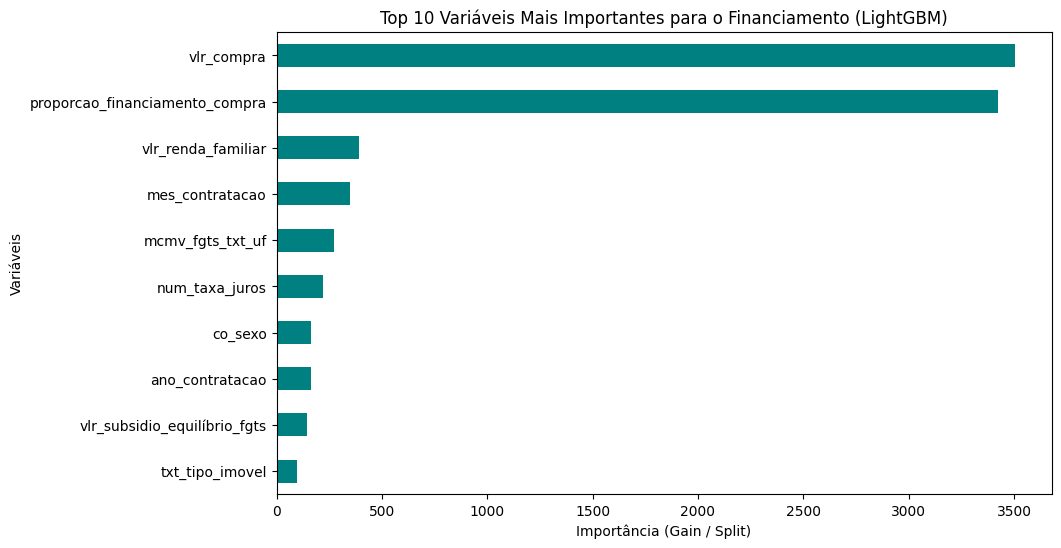

In [53]:
# Célula de Código: Gráfico de Importância das Variáveis
import matplotlib.pyplot as plt
import seaborn as plt_sns
import pandas as pd

# Usamos as colunas de X_train que representam exatamente as features usadas no treinamento
importances = pd.Series(lgb_model.feature_importances_, index=X_train.columns)
plt.figure(figsize=(10, 6))
importances.nlargest(10).plot(kind='barh', color='teal')
plt.title('Top 10 Variáveis Mais Importantes para o Financiamento (LightGBM)')
plt.xlabel('Importância (Gain / Split)')
plt.ylabel('Variáveis')
plt.gca().invert_yaxis()
plt.show()

In [54]:
# 1. Criando um DataFrame simulado para o ano de 2027
fator_ajuste_inflacao = 1.04

# Pegando uma amostra recente de operações de 2026 para servir de base para o perfil de 2027
df_base_2027 = df[df['ano_assinatura'] == df['ano_assinatura'].max()].sample(n=5000, random_state=42).copy()

# Simulando uma evolução nas variáveis econômicas para 2027
df_base_2027['vlr_compra'] = df_base_2027['vlr_compra'] * fator_ajuste_inflacao
df_base_2027['vlr_renda_familiar'] = df_base_2027['vlr_renda_familiar'] * fator_ajuste_inflacao
df_base_2027['ano_assinatura'] = 2027 # Atualizando o ano de referência

# 2. Garantindo que as features usadas na projeção sejam exatamente as mesmas do treino (removendo 'ano_mes')
features_validas = [col for col in features if col != 'ano_mes']
X_projecao_2027 = df_base_2027[features_validas].copy()

# Para colunas categóricas no LightGBM, garanta que o tipo seja 'category'
for col in X_projecao_2027.select_dtypes(include=['object', 'string']).columns:
    X_projecao_2027[col] = X_projecao_2027[col].astype('category')

# 3. Gerando a Projeção do Valor de Financiamento para 2027
df_base_2027['vlr_financiamento_projetado_2027'] = lgb_model.predict(X_projecao_2027)

# 4. Analisando os resultados projetados por Região ou Tipo de Imóvel
projecao_por_regiao = df_base_2027.groupby('txt_regiao').agg(
    ticket_medio_compra=('vlr_compra', 'mean'),
    ticket_medio_financiamento=('vlr_financiamento_projetado_2027', 'mean'),
    financiamento_medio_projetado=('vlr_financiamento_projetado_2027', 'mean'),
    renda_media=('vlr_renda_familiar', 'mean'),
    total_operacoes=('vlr_financiamento_projetado_2027', 'count')
).round(2).reset_index()

print("--- PROJEÇÃO MÉDIA POR REGIÃO PARA 2027 ---")
display(projecao_por_regiao)

--- PROJEÇÃO MÉDIA POR REGIÃO PARA 2027 ---


,txt_regiao,ticket_medio_compra,ticket_medio_financiamento,financiamento_medio_projetado,renda_media,total_operacoes
0,CENTRO-OESTE,262437.75,7860415.86,7860415.86,323633.03,651
1,NORDESTE,224846.23,8507908.86,8507908.86,225170.38,1070
2,NORTE,241596.29,7727383.96,7727383.96,311023.55,193
3,SUDESTE,278981.96,8905158.91,8905158.91,382327.35,2258
4,SUL,285415.58,7247733.49,7247733.49,444892.44,828
